In [1]:
!pip install pyfixest[jax]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.7/115.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.2/607.2 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.9 MB/s eta 0:00:00


In [2]:
!pip install linearmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.9/43.9 kB 1.8 MB/s eta 0:00:00


In [3]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
from pyfixest.estimation import feols
import scipy.stats
import numpy as np
from matplotlib.lines import Line2D
import linearmodels as lm



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Mounted at /content/gdrive


In [4]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0041
Estimator:                   PanelOLS   R-squared (Between):              0.0009
No. Observations:                6214   R-squared (Within):               0.0004
Date:                Fri, Apr 11 2025   R-squared (Overall):              0.0023
Time:                        05:23:12   Log-likelihood                -5.788e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      5.0259
Entities:                          29   P-value                           0.0001
Avg Obs:                       214.28   Distribution:                  F(5,6154)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             8.8740
                            

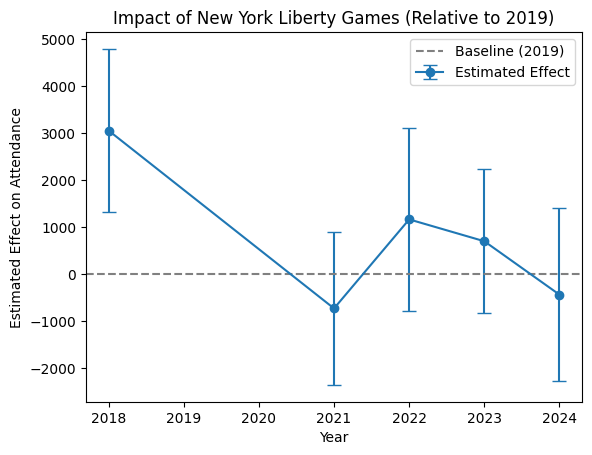

In [6]:
# Minnesota Lynx (Napheesa Collier)
min_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for New York Liberty Games (2019-2024)
min_attendance_df['MN_Lynx_Game'] = (min_attendance_df['Home Team'] == 'Minnesota Lynx') & (min_attendance_df['Year'].between(2018, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Omit 2019; Skip 2020 as the Reference)
for year in [2018, 2021, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    min_attendance_df[col_name] = min_attendance_df['MN_Lynx_Game'].astype(int)
    min_attendance_df.loc[min_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
min_attendance_df = min_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2018 + INX2021 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2019]',
    min_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2018, 2021, 2022, 2023, 2024]  # Excluding 2019 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2019)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of New York Liberty Games (Relative to 2019)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0027
Estimator:                   PanelOLS   R-squared (Between):              0.0010
No. Observations:                6214   R-squared (Within):              -0.0030
Date:                Fri, Apr 11 2025   R-squared (Overall):              0.0019
Time:                        05:27:09   Log-likelihood                -5.788e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      4.1034
Entities:                          29   P-value                           0.0025
Avg Obs:                       214.28   Distribution:                  F(4,6155)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             2.0395
                            

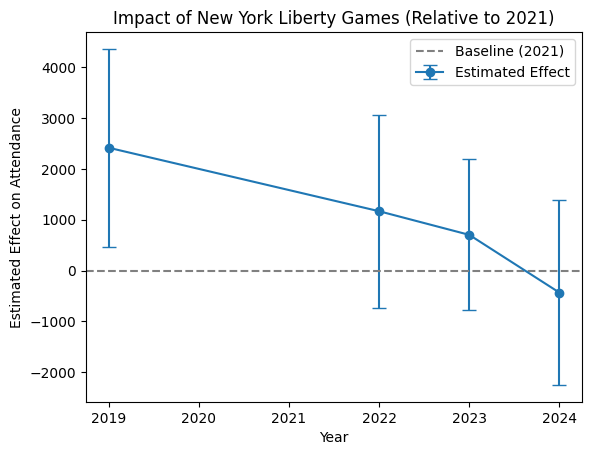

In [8]:
# Minnesota Lynx (Kayla McBride)
min_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for New York Liberty Games (2021-2024)
min_attendance_df['MN_Lynx_Game'] = (min_attendance_df['Home Team'] == 'Minnesota Lynx') & (min_attendance_df['Year'].between(2019, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Omit 2021; Skip 2020 as the Reference)
for year in [2019, 2022, 2023, 2024]:
    col_name = f'INX{year}'
    min_attendance_df[col_name] = min_attendance_df['MN_Lynx_Game'].astype(int)
    min_attendance_df.loc[min_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
min_attendance_df = min_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2019 + INX2022 + INX2023 + INX2024 + EntityEffects + TimeEffects - TimeEffects[2021]',
    min_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2019, 2022, 2023, 2024]  # Excluding 2021 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2021)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of New York Liberty Games (Relative to 2021)")
plt.legend()
plt.show()


                          PanelOLS Estimation Summary                           
Dep. Variable:             Attendance   R-squared:                        0.0006
Estimator:                   PanelOLS   R-squared (Between):              0.0005
No. Observations:                6214   R-squared (Within):              -0.0014
Date:                Fri, Apr 11 2025   R-squared (Overall):              0.0010
Time:                        05:30:24   Log-likelihood                -5.789e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1.7285
Entities:                          29   P-value                           0.1776
Avg Obs:                       214.28   Distribution:                  F(2,6157)
Min Obs:                       1.0000                                           
Max Obs:                       503.00   F-statistic (robust):             0.7165
                            

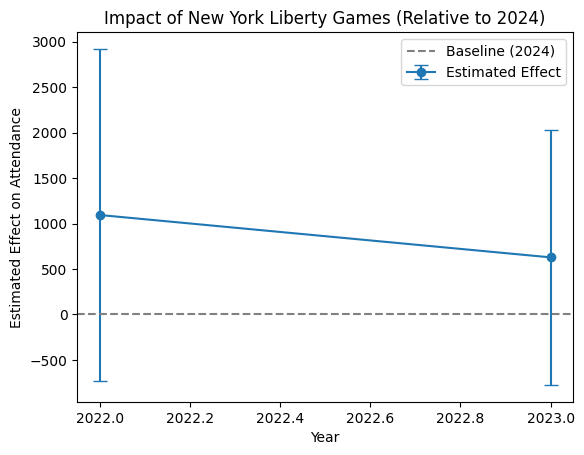

In [12]:
# Minnesota Lynx (Alanna Smith)
min_attendance_df = attendance_df.copy()

# 🚀 2. Create Treatment Variable for New York Liberty Games (2024)
min_attendance_df['MN_Lynx_Game'] = (min_attendance_df['Home Team'] == 'Minnesota Lynx') & (min_attendance_df['Year'].between(2022, 2024))

# 🚀 3. Create Interaction Terms for Each Year (Skip 2024 as the Reference)
for year in [2022, 2023]:
    col_name = f'INX{year}'
    min_attendance_df[col_name] = min_attendance_df['MN_Lynx_Game'].astype(int)
    min_attendance_df.loc[min_attendance_df['Year'] != year, col_name] = 0

# 🚀 4. Set Index for Panel Data (Team and Year)
min_attendance_df = min_attendance_df.set_index(['Home Team', 'Year'])

# 🚀 5. Define and Fit Panel Regression Model
mod = lm.PanelOLS.from_formula(
    'Attendance ~ INX2022 + INX2023 + EntityEffects + TimeEffects - TimeEffects[2024]',
    min_attendance_df
)
clfe = mod.fit(cov_type='clustered', cluster_entity=True)
print(clfe.summary)

# 🚀 6. Extract Coefficients and Confidence Intervals
res = pd.concat([clfe.params, clfe.std_errors], axis=1)
res.columns = ['parameter', 'std_error']
res['ci'] = res['std_error'] * 1.96  # 95% CI
res['Year'] = [2022, 2023]  # Excluding 2024 as the reference

# Print results table
print("\n📊 Coefficients & Confidence Intervals:")
print(res)

# 🚀 7. Plot the Results
plt.errorbar(x=res['Year'], y=res['parameter'], yerr=res['ci'], fmt='o-', capsize=5, label="Estimated Effect")
plt.axhline(0, linestyle='dashed', color='gray', label="Baseline (2024)")
plt.xlabel("Year")
plt.ylabel("Estimated Effect on Attendance")
plt.title("Impact of New York Liberty Games (Relative to 2024)")
plt.legend()
plt.show()
